# 9. Tujuan 5: kecukupan jaringan pemantauan

Jarak antarstasiun (Haversine), keandalan data PM2.5 (andal bila minimal 90% jam terisi), provinsi tanpa stasiun andal, skor prioritas dari beban pencemaran dan kesehatan serta kesenjangan pemantauan, uji kepekaan terhadap empat skenario bobot, dan stasiun yang paling awal memasuki episode asap.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import pandas as pd
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
%matplotlib inline

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

MART = "../data/mart/"
CLEAN = "../data/clean/"
OUT = "../hasil/"
GAMBAR = OUT + "gambar/"
AMBANG_ANDAL = 90.0

In [3]:
dim = pd.read_csv(MART + "dim_lokasi.csv")
a = pd.read_csv(CLEAN + "air_hourly_clean.csv", usecols=["stasiun", "pm25"])
kel = a.groupby("stasiun")["pm25"].apply(lambda s: s.notna().mean() * 100)
pm_jam = a.groupby("stasiun")["pm25"].mean()
harian = pd.read_csv(MART + "fakta_udara_harian.csv")
v = harian[harian["hari_valid"]]
ag = v.groupby("stasiun").agg(hari_valid=("pm25", "size"), pm25_rata2=("pm25", "mean"),
                              pct_tidak_sehat=("ispu", lambda s: (s > 100).mean() * 100),
                              pct_lewat_bm=("lewat_bm_pm25", "mean"))
ag["pct_lewat_bm"] *= 100
ep = pd.read_csv(MART + "fakta_episode_asap.csv", parse_dates=["mulai", "selesai"])
ep_ag = ep.groupby("stasiun").agg(jumlah_episode=("id_episode", "size"), hari_episode=("durasi_hari", "sum"))
sehat = pd.read_csv(MART + "fakta_kesehatan_harian.csv")
sehat["ispa_total"] = sehat["resp_admissions_under5"] + sehat["resp_admissions_over60"]
hs = sehat.groupby("hospital_id").agg(ispa_per_hari=("ispa_total", "mean"), kematian_per_hari=("death", "mean"))

In [4]:
j = dim[["stasiun", "location_id", "provinsi", "pulau", "kategori_lokasi", "site_type", "wilayah_gambut", "latitude", "longitude",
         "status_operasional", "tanggal_instalasi", "traffic_intensity_per_h", "distance_to_road_m", "baseline_pm25",
         "hospital_id", "kapasitas_tempat_tidur", "kelas_faskes", "status_analisis"]].copy()
j = j.set_index("stasiun").join(ag).join(ep_ag).join(hs, on="hospital_id")
j["kelengkapan_pm25_pct"] = kel.reindex(j.index)
j.loc["JMB-02", "kelengkapan_pm25_pct"] = 0.5
j.loc["MER-01", "pm25_rata2"] = pm_jam["MER-01"]
j[["jumlah_episode", "hari_episode"]] = j[["jumlah_episode", "hari_episode"]].fillna(0)
j.loc["MER-01", "pct_tidak_sehat"] = 0.0
j.loc["MER-01", "pct_lewat_bm"] = 0.0
j["ispa_per_100_tt"] = j["ispa_per_hari"] / j["kapasitas_tempat_tidur"] * 100
j["andal"] = j["kelengkapan_pm25_pct"] >= AMBANG_ANDAL

In [5]:
def hav(lat1, lon1, lat2, lon2):
    R = 6371.0
    p1, p2 = np.radians(lat1), np.radians(lat2)
    dl = np.radians(lon2 - lon1)
    dp = p2 - p1
    x = np.sin(dp / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(dl / 2) ** 2
    return 2 * R * np.arcsin(np.sqrt(x))

In [6]:
st = j.index.tolist()
D = pd.DataFrame([[hav(j.loc[a_, "latitude"], j.loc[a_, "longitude"], j.loc[b_, "latitude"], j.loc[b_, "longitude"]) for b_ in st]
                  for a_ in st], index=st, columns=st)
nn, nn_nama, nr, nr_nama = [], [], [], []
for s in st:
    x = D.loc[s].drop(s)
    nn.append(x.min())
    nn_nama.append(x.idxmin())
    y = x[j.loc[x.index, "andal"]]
    nr.append(y.min())
    nr_nama.append(y.idxmin())
j["jarak_terdekat_km"] = nn
j["stasiun_terdekat"] = nn_nama
j["jarak_andal_terdekat_km"] = nr
j["stasiun_andal_terdekat"] = nr_nama

In [7]:
skor = j.drop(index="JMB-02").copy()

In [8]:
def mm(s):
    return (s - s.min()) / (s.max() - s.min())


skor["b_pm25"] = mm(skor["pm25_rata2"])
skor["b_tidak_sehat"] = mm(skor["pct_tidak_sehat"])
skor["b_episode"] = mm(skor["hari_episode"])
skor["b_kesehatan"] = mm(skor["ispa_per_100_tt"])
skor["g_ketidakandalan"] = mm(100 - skor["kelengkapan_pm25_pct"])
skor["g_keterpencilan"] = mm(np.log10(skor["jarak_andal_terdekat_km"]))
skor["indeks_beban"] = skor[["b_pm25", "b_tidak_sehat", "b_episode", "b_kesehatan"]].mean(axis=1)
skor["indeks_kesenjangan"] = skor[["g_ketidakandalan", "g_keterpencilan"]].mean(axis=1)
skor["skor_prioritas"] = 100 * (skor["indeks_beban"] + skor["indeks_kesenjangan"]) / 2
med_beban = skor["indeks_beban"].median()
ambang_terpencil = skor["jarak_andal_terdekat_km"].median()

In [9]:
def tindakan(r):
    if r["kelengkapan_pm25_pct"] < AMBANG_ANDAL:
        return "Perbaiki atau ganti sensor"
    if r["jarak_andal_terdekat_km"] >= ambang_terpencil and r["indeks_beban"] >= med_beban:
        return "Tambah titik pendamping"
    if r["indeks_beban"] >= med_beban:
        return "Pertahankan (beban tinggi)"
    return "Pertahankan"

In [10]:
skor["tindakan"] = skor.apply(tindakan, axis=1)
skor["peringkat"] = skor["skor_prioritas"].rank(ascending=False, method="min").astype(int)

j = j.join(skor[["indeks_beban", "indeks_kesenjangan", "skor_prioritas", "peringkat", "tindakan",
                 "b_pm25", "b_tidak_sehat", "b_episode", "b_kesehatan", "g_ketidakandalan", "g_keterpencilan"]])
j.loc["JMB-02", "tindakan"] = "Perbaiki dan relokasikan"
j["catatan"] = ""
j.loc["JMB-02", "catatan"] = "Koordinat hanya 0,9 km dari JMB-01 sehingga tidak menambah cakupan; sensor rusak"
j.loc["MER-01", "catatan"] = "Data valid hanya 23%; 1.319 km dari stasiun terdekat"
j.loc["SM2-01", "catatan"] = "Kode galat 999 pada musim asap; puncak asap kemungkinan terpotong"
j.loc["BJB-01", "catatan"] = "Sensor macet 7 bulan (Sep 2024 - Mar 2025) berstatus VALID"
j.loc["MDN-01", "catatan"] = "Celah data rutin 3 jam dan gangguan 3-5 hari; RS terbesar (720 tempat tidur)"
j.loc["PLB-01", "catatan"] = "Resolusi campuran 1 jam dan 15 menit; 14% data hilang"
j = j.reset_index()

In [11]:
sens = []
base = skor["skor_prioritas"]
skenarios = {
    "Bobot sama (utama)": (0.5, 0.5),
    "Beban lebih penting (70:30)": (0.7, 0.3),
    "Kesenjangan lebih penting (30:70)": (0.3, 0.7),
}
for nama, (wb, wg) in skenarios.items():
    s_ = 100 * (wb * skor["indeks_beban"] + wg * skor["indeks_kesenjangan"])
    sens.append(pd.DataFrame({"stasiun": skor.index, "skenario": nama, "skor": s_.values, "peringkat": s_.rank(ascending=False, method="min").values}))
for nama, kol in [("Tanpa hari episode", ["b_pm25", "b_tidak_sehat", "b_kesehatan"]), ("Tanpa beban kesehatan", ["b_pm25", "b_tidak_sehat", "b_episode"])]:
    b_ = skor[kol].mean(axis=1)
    s_ = 100 * (b_ + skor["indeks_kesenjangan"]) / 2
    sens.append(pd.DataFrame({"stasiun": skor.index, "skenario": nama, "skor": s_.values, "peringkat": s_.rank(ascending=False, method="min").values}))
sens = pd.concat(sens)
sens_p = sens.pivot(index="stasiun", columns="skenario", values="peringkat")
rho_sens = {c: round(spearmanr(sens_p["Bobot sama (utama)"], sens_p[c])[0], 3) for c in sens_p.columns if c != "Bobot sama (utama)"}
top5 = {c: set(sens_p.nsmallest(5, c).index) for c in sens_p.columns}
irisan = {c: len(top5["Bobot sama (utama)"] & top5[c]) for c in sens_p.columns if c != "Bobot sama (utama)"}

In [12]:
prov = j.groupby(["provinsi", "pulau"]).agg(jumlah_stasiun=("stasiun", "size"), stasiun_andal=("andal", "sum"),
                                            pm25_rata2=("pm25_rata2", "mean"), hari_episode=("hari_episode", "sum")).reset_index()
prov["stasiun_andal"] = prov["stasiun_andal"].astype(int)
prov["tanpa_stasiun_andal"] = prov["stasiun_andal"] == 0

ep["tahun"] = ep["mulai"].dt.year
awal = ep.groupby(["tahun", "stasiun"])["mulai"].min().reset_index()
sent = []
for th, g in awal.groupby("tahun"):
    g = g.sort_values("mulai").reset_index(drop=True)
    g["urutan_terdeteksi"] = range(1, len(g) + 1)
    g["hari_lebih_awal_dari_terakhir"] = (g["mulai"].max() - g["mulai"]).dt.days
    g["hari_lebih_awal_dari_median"] = (g["mulai"].median() - g["mulai"]).dt.days
    sent.append(g)
sent = pd.concat(sent).merge(dim[["stasiun", "provinsi", "kategori_lokasi"]], on="stasiun")
sent_ring = sent.groupby("stasiun").agg(tahun_terlibat=("tahun", "size"), rata2_hari_lebih_awal_dari_median=("hari_lebih_awal_dari_median", "mean"),
                                        kali_terdeteksi_pertama=("urutan_terdeteksi", lambda s: int((s == 1).sum()))).round(1).reset_index()

In [13]:
tipe = j.groupby("kategori_lokasi").agg(jumlah=("stasiun", "size"), andal=("andal", "sum"), trafik_median=("traffic_intensity_per_h", "median")).reset_index()
tinggi_trafik = j[(j["traffic_intensity_per_h"] >= 2000)][["stasiun", "provinsi", "kategori_lokasi", "traffic_intensity_per_h", "distance_to_road_m"]].sort_values("traffic_intensity_per_h", ascending=False)

terdekat = j[["stasiun", "stasiun_terdekat", "jarak_terdekat_km", "stasiun_andal_terdekat", "jarak_andal_terdekat_km"]].round(1)
dekat_km = {"≤ 20 km": int((j["jarak_terdekat_km"] <= 20).sum()), "20–200 km": int(((j["jarak_terdekat_km"] > 20) & (j["jarak_terdekat_km"] <= 200)).sum()),
            "200–500 km": int(((j["jarak_terdekat_km"] > 200) & (j["jarak_terdekat_km"] <= 500)).sum()), "> 500 km": int((j["jarak_terdekat_km"] > 500).sum())}

kolom_csv = ["stasiun", "provinsi", "pulau", "kategori_lokasi", "wilayah_gambut", "latitude", "longitude", "status_operasional", "status_analisis",
             "hospital_id", "kapasitas_tempat_tidur", "kelengkapan_pm25_pct", "andal", "hari_valid", "pm25_rata2", "pct_tidak_sehat", "pct_lewat_bm",
             "jumlah_episode", "hari_episode", "ispa_per_hari", "ispa_per_100_tt", "kematian_per_hari", "traffic_intensity_per_h",
             "stasiun_terdekat", "jarak_terdekat_km", "stasiun_andal_terdekat", "jarak_andal_terdekat_km",
             "indeks_beban", "indeks_kesenjangan", "skor_prioritas", "peringkat", "tindakan", "catatan"]
jc = j[kolom_csv].copy()
for c in ["kelengkapan_pm25_pct", "pm25_rata2", "pct_tidak_sehat", "pct_lewat_bm", "ispa_per_hari", "ispa_per_100_tt", "kematian_per_hari",
          "jarak_terdekat_km", "jarak_andal_terdekat_km", "skor_prioritas"]:
    jc[c] = jc[c].round(1)
for c in ["indeks_beban", "indeks_kesenjangan"]:
    jc[c] = jc[c].round(3)
jc["andal"] = jc["andal"].map({True: "Andal (≥ 90% data)", False: "Tidak andal"})
jc["tindakan"] = jc["tindakan"].fillna("Pertahankan")
jc["peringkat"] = jc["peringkat"].astype("Int64")
jc.to_csv(MART + "fakta_jaringan_stasiun.csv", index=False)
prov.round(1).to_csv(MART + "fakta_jaringan_provinsi.csv", index=False)
sent.assign(mulai=sent["mulai"].dt.date).to_csv(MART + "fakta_sentinel_episode.csv", index=False)

In [14]:
with pd.ExcelWriter(OUT + "09_T5_kecukupan_jaringan.xlsx") as w:
    jc.sort_values("peringkat").to_excel(w, sheet_name="stasiun_dan_prioritas", index=False)
    skor[["indeks_beban", "indeks_kesenjangan", "skor_prioritas", "peringkat", "tindakan"]].round(3).reset_index().sort_values("peringkat").to_excel(w, sheet_name="skor_ringkas", index=False)
    sens_p.reset_index().to_excel(w, sheet_name="sensitivitas_peringkat", index=False)
    prov.round(1).to_excel(w, sheet_name="per_provinsi", index=False)
    tipe.to_excel(w, sheet_name="komposisi_tipe_lokasi", index=False)
    tinggi_trafik.to_excel(w, sheet_name="stasiun_trafik_tinggi", index=False)
    terdekat.to_excel(w, sheet_name="jarak_terdekat", index=False)
    sent_ring.to_excel(w, sheet_name="sentinel_ringkas", index=False)
    sent.assign(mulai=sent["mulai"].dt.date).to_excel(w, sheet_name="awal_episode_per_tahun", index=False)

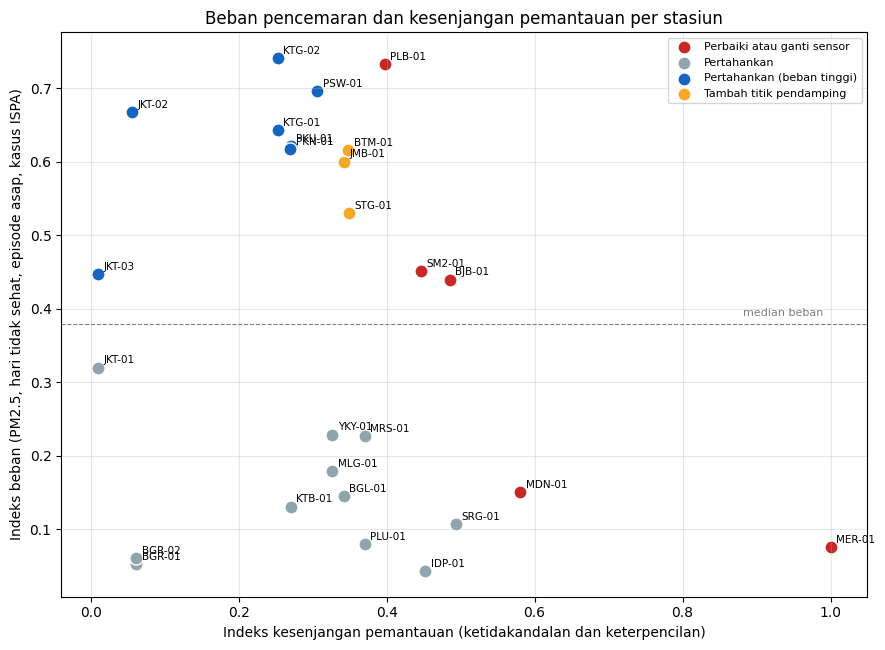

In [15]:
WARNA = {"Perbaiki atau ganti sensor": "#c62828", "Perbaiki dan relokasikan": "#8e24aa", "Tambah titik pendamping": "#f9a825",
         "Pertahankan (beban tinggi)": "#1565c0", "Pertahankan": "#90a4ae"}
fig, ax = plt.subplots(figsize=(9, 6.6))
for t, g in skor.assign(tindakan=skor["tindakan"]).groupby("tindakan"):
    ax.scatter(g["indeks_kesenjangan"], g["indeks_beban"], s=90, color=WARNA[t], label=t, edgecolor="white")
    for s_, r in g.iterrows():
        ax.annotate(s_, (r["indeks_kesenjangan"], r["indeks_beban"]), fontsize=7.5, xytext=(4, 3), textcoords="offset points")
ax.axhline(med_beban, color="grey", ls="--", lw=0.8)
ax.text(0.99, med_beban + 0.01, "median beban", ha="right", fontsize=8, color="grey")
ax.set_xlabel("Indeks kesenjangan pemantauan (ketidakandalan dan keterpencilan)")
ax.set_ylabel("Indeks beban (PM2.5, hari tidak sehat, episode asap, kasus ISPA)")
ax.set_title("Beban pencemaran dan kesenjangan pemantauan per stasiun")
ax.legend(fontsize=8, loc="upper right")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(GAMBAR + "09_T5_beban_vs_kesenjangan.png", dpi=150)
plt.show()

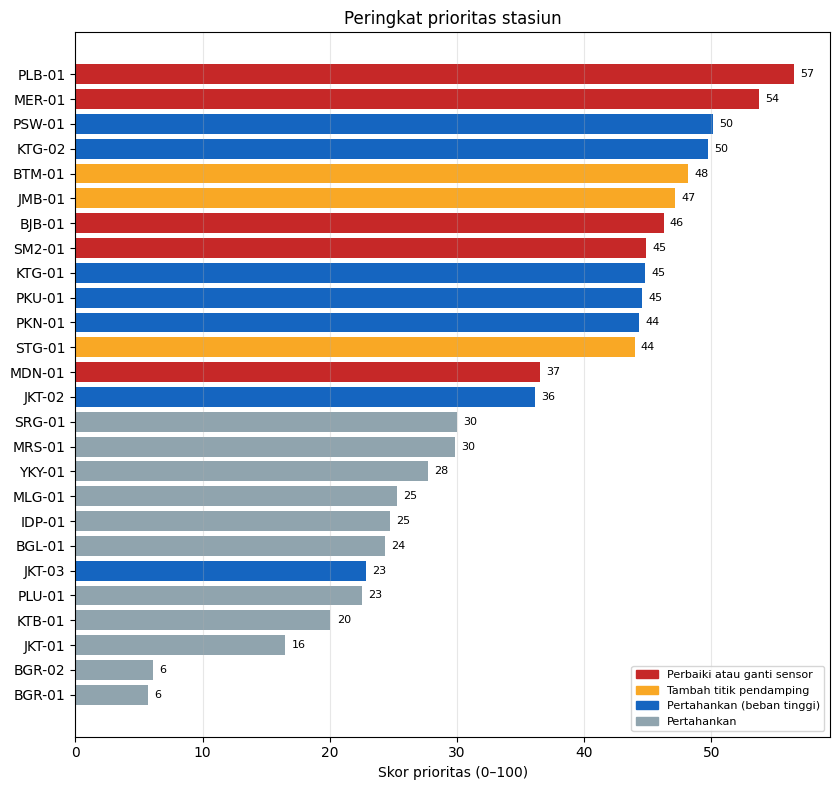

In [16]:
pr = skor.sort_values("skor_prioritas")
fig, ax = plt.subplots(figsize=(8.5, 8))
ax.barh(pr.index, pr["skor_prioritas"], color=[WARNA[t] for t in pr["tindakan"]])
for y, vv in enumerate(pr["skor_prioritas"]):
    ax.text(vv + 0.5, y, f"{vv:.0f}", va="center", fontsize=8)
ax.set_xlabel("Skor prioritas (0–100)")
ax.set_title("Peringkat prioritas stasiun")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for k, c in WARNA.items() if k in set(pr["tindakan"])],
          labels=[k for k in WARNA if k in set(pr["tindakan"])], fontsize=8, loc="lower right")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig(GAMBAR + "09_T5_peringkat_prioritas.png", dpi=150)
plt.show()

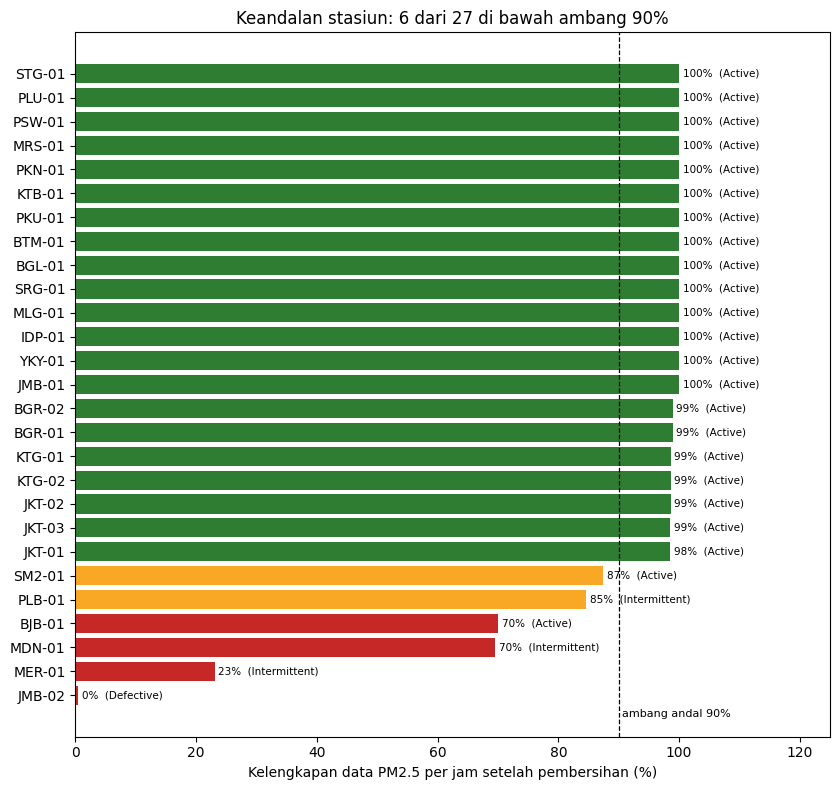

In [17]:
kr = j.sort_values("kelengkapan_pm25_pct")
fig, ax = plt.subplots(figsize=(8.5, 8))
ax.barh(kr["stasiun"], kr["kelengkapan_pm25_pct"], color=["#c62828" if x < 75 else "#f9a825" if x < 90 else "#2e7d32" for x in kr["kelengkapan_pm25_pct"]])
ax.axvline(AMBANG_ANDAL, color="black", ls="--", lw=0.9)
ax.text(AMBANG_ANDAL + 0.5, -0.9, "ambang andal 90%", fontsize=8)
for y, (vv, stt) in enumerate(zip(kr["kelengkapan_pm25_pct"], kr["status_operasional"])):
    ax.text(vv + 0.6, y, f"{vv:.0f}%  ({stt})", va="center", fontsize=7.5)
ax.set_xlim(0, 125)
ax.set_xlabel("Kelengkapan data PM2.5 per jam setelah pembersihan (%)")
ax.set_title("Keandalan stasiun: 6 dari 27 di bawah ambang 90%")
plt.tight_layout()
plt.savefig(GAMBAR + "09_T5_keandalan_stasiun.png", dpi=150)
plt.show()

In [18]:
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 40)
print(jc.sort_values("peringkat")[["stasiun", "provinsi", "kelengkapan_pm25_pct", "pm25_rata2", "pct_tidak_sehat", "hari_episode", "ispa_per_100_tt",
                                  "jarak_andal_terdekat_km", "indeks_beban", "indeks_kesenjangan", "skor_prioritas", "peringkat", "tindakan"]].to_string())
print(jc[jc["stasiun"] == "JMB-02"][["stasiun", "kelengkapan_pm25_pct", "stasiun_andal_terdekat", "jarak_andal_terdekat_km", "tindakan"]])
print("ambang terpencil (median jarak ke stasiun andal terdekat, km):", round(ambang_terpencil, 1))
print("provinsi tanpa stasiun andal:", prov.loc[prov["tanpa_stasiun_andal"], "provinsi"].tolist())
print("median beban", round(med_beban, 3), "| andal:", int(j["andal"].sum()), "dari", len(j))
print(sens_p.sort_values("Bobot sama (utama)").to_string())
print("rho sensitivitas", rho_sens, "irisan top5", irisan)
print(prov.round(1).to_string())
print(tipe.to_string())
print(tinggi_trafik.to_string())
print(dekat_km)
print(sent_ring.sort_values("rata2_hari_lebih_awal_dari_median", ascending=False).to_string())
print(jc["tindakan"].value_counts().to_dict())

   stasiun            provinsi  kelengkapan_pm25_pct  pm25_rata2  pct_tidak_sehat  hari_episode  ispa_per_100_tt  jarak_andal_terdekat_km  indeks_beban  indeks_kesenjangan  skor_prioritas  peringkat                    tindakan
20  PLB-01    Sumatera Selatan                  84.6        67.2             27.6         233.0             12.4                    187.3         0.733               0.397            56.5          1  Perbaiki atau ganti sensor
22  MER-01       Papua Selatan                  23.1        16.0              0.0           0.0              3.9                   1318.7         0.075               1.000            53.8          2  Perbaiki atau ganti sensor
21  PSW-01             Lampung                 100.0        50.7             25.4         235.0             13.9                    203.8         0.697               0.306            50.1          3  Pertahankan (beban tinggi)
4   KTG-02   Kalimantan Tengah                  98.6        61.1             23.9         24